# FuzzyQSM on one simulated TLS tree — minimal reproduction

**Paper:** V. Verhoeven et al., *FuzzyQSM: A Novel Tree Structure Reconstruction Approach Using Uncertainty*, **Remote Sensing 18(18):3244**, MDPI, 2026. DOI: [10.3390/rs18183244](https://doi.org/10.3390/rs18183244)
**Author code:** [InverseTampere/FuzzyQSM](https://github.com/InverseTampere/FuzzyQSM) @ commit `0e8496b` (GPL-3.0, MATLAB R2024b)
**Data:** [Zenodo record 20793837](https://zenodo.org/records/20793837) — `FuzzyQSM_Data.zip` (5.96 GB, CC-BY-4.0, md5 `129c5d244c793b3b56ffc9b1fb4a65dd`)

**Scope (partial demonstration, CPU):** for one simulated Wytham Woods tree (`ACERPS_1544`, 0.30 mrad beam divergence, 2 scanning positions):
1. reproduce the paper's **volume-accuracy comparison** (total / stem / branch volume of the provided TreeQSM and FuzzyQSM reconstructions against the smoothed-model ground truth) using the exact author metric `sum(pi*r^2*L)` per branch order;
2. **execute the authors' own fuzzy cylinder-fitting code** (`Fuzzy_QSM_Infinite_Cylinder_Fitting.m`) under GNU Octave on one stem cylinder, and compare the refitted radius against the authors' released FuzzyQSM radius and the TreeQSM initial radius.

**Not executed / out of scope:** Helios++ simulation, noise addition, TreeQSM refitting, full-tree fuzzy fitting, the paper's dataset-level statistics. One tree is not verification of the published dataset-level averages (total volume underestimation 6.3% FuzzyQSM vs 16.9% TreeQSM; branch 2.2% vs 22.2%, from the abstract).

**AI-assisted adaptation notice (EN):** The authors' implementation is MATLAB R2024b + Optimization Toolbox. This notebook runs the **authors' original functions unmodified** under GNU Octave, except for three clearly labeled AI-generated compatibility files written below (`fmincon`→`sqp` adapter, `optimoptions` shim, and a replacement for `Vector_Spherical_Angle_Conversion`, which the released repository calls but does not include). The Python volume metric is a direct transcription of `QSM_Branch_Metrics.m`/`QSM_Tree_Metrics.m`. Untested behavior is not guaranteed; the authors did not provide this Colab implementation.

**AI支援に関する注意（JA）：** 著者のMATLAB実装をGNU Octave上でほぼそのまま実行します。生成した互換アダプタ3点（fmincon→sqp、optimoptions、未公開関数の代替）とPythonの体積計算はAI作成であり、検証済みの範囲のみを保証します。著者提供のColab実装ではありません。

**Runtime:** select **CPU runtime** (no GPU is used anywhere in this method). Expected wall time ≈ 30–40 min, dominated by the one-time 5.96 GB dataset download (≈ 25 min measured on 2026-10-24; the full archive must be downloaded because Zenodo serves it as a single zip — this exceeds the 2 GiB soft target by necessity, and only this tree's files are extracted).

**実行環境（JA）：** CPU ランタイムで実行してください（GPU不要）。所要時間は約30–40分、うちZenodo からの 5.96 GB ダウンロードが約25分です（単一 zip のため部分取得は不可）。

**Environment check.** Verify free disk (the 6 GB archive plus extraction need room), CPU count, and Python before any download.

**環境確認（JA）：** ディスク空き容量・CPU数・Pythonを確認します。

In [ ]:
import subprocess, os, sys, time
print(subprocess.run(["df","-h","/content"],capture_output=True,text=True).stdout)
print("python:", sys.version.split()[0], "| cpus:", os.cpu_count())

Filesystem      Size  Used Avail Use% Mounted on
overlay         226G   27G  200G  12% /

python: 3.13.16 | cpus: 2


**Dependencies.** `scipy`/`numpy`/`matplotlib` are preinstalled on Colab. Install GNU Octave and its statistics package (the authors' `Point_Cloud_Multivariate_Normal_Generation.m` calls `chi2inv`, which lives there).

**依存関係（JA）：** Octave と statistics パッケージ（chi2inv に必要）をインストールします。

In [ ]:
import subprocess, time
t0=time.time()
for cmd in [["sudo","apt-get","update","-qq"],["sudo","apt-get","install","-y","-qq","octave","octave-statistics"]]:
    r=subprocess.run(cmd,capture_output=True,text=True)
    print(" ".join(cmd[2:4]), "rc:", r.returncode)
    assert r.returncode==0, r.stderr[-500:]
r=subprocess.run(["octave","--version"],capture_output=True,text=True)
print(r.stdout.splitlines()[0], f"(install {time.time()-t0:.0f}s)")

update -qq rc: 0


install -y rc: 0
GNU Octave, version 8.4.0 (install 8s)


**Pinned author code.** Blobless sparse checkout of `InverseTampere/FuzzyQSM` at the verified commit `0e8496b` (GPL-3.0), inside the Colab VM only. The checked-out commit is asserted. The numerical directories of the repository are placed on the Octave path later; vendored plotting tools (`Colorbrewer/`, `Export_Fig/`) are not needed headless.

**ピン留めした著者コード（JA）：** 検証済みコミット `0e8496b` を blobless sparse clone で取得し、コミットを検証します。

In [ ]:
import subprocess, os
os.chdir("/content")
FQ_COMMIT="0e8496b52df652377af5fdb4fb5baa66ad8341a6"
env=dict(os.environ, GIT_LFS_SKIP_SMUDGE="1", GIT_TERMINAL_PROMPT="0")
if not os.path.exists("/content/fuzzyqsm_code"):
    r=subprocess.run(["git","clone","--filter=blob:none","--no-checkout","--quiet",
                      "https://github.com/InverseTampere/FuzzyQSM.git","/content/fuzzyqsm_code"],
                     env=env,capture_output=True,text=True)
    assert r.returncode==0, r.stderr[-300:]
def g(*a):
    rr=subprocess.run(["git","-C","/content/fuzzyqsm_code"]+list(a),capture_output=True,text=True,env=env)
    assert rr.returncode==0, rr.stderr[-300:]
g("sparse-checkout","init","--cone")
g("sparse-checkout","set","FuzzyQSM","Geometry","Shape_Fitting","Multivariate_Gaussian","Laser_Properties",
  "Matrix","Roots","Structures","Point_Cloud_Processing","Miscellaneous")
g("checkout",FQ_COMMIT)
head=subprocess.run(["git","-C","/content/fuzzyqsm_code","rev-parse","HEAD"],capture_output=True,text=True).stdout.strip()
assert head==FQ_COMMIT, head
print("checked out:", head)

checked out: 0e8496b52df652377af5fdb4fb5baa66ad8341a6


**Octave compatibility files (AI-generated, clearly labeled).** Three gaps between the author's MATLAB R2024b toolchain and GNU Octave 8.4:
1. `fmincon.m` — the authors optimize each cylinder with MATLAB `fmincon` (interior-point, fallback `sqp`; `Fuzzy_QSM_Infinite_Cylinder_Fitting.m` lines 214–228). Octave core has no `fmincon`; the adapter maps the identical box-bounded call to Octave core `sqp()` — the same algorithm class as the authors' own fallback. The Hessian output is omitted (used by the authors only for a convexity warning).
2. `optimoptions.m` — stores the options in a plain struct (the adapter consumes `MaxIterations` only).
3. `Vector_Spherical_Angle_Conversion.m` — **called but not released**: verified via the GitHub tree API (169 entries at the pinned commit, no such file; also absent from InverseTampere/TreeQSM). The replacement implements the standard MATLAB spherical convention, the only convention consistent with the author's own usage (`pitch = pi/4` initialisation; the axis' final component is forced positive in `Geometry_Retrieval`).

**互換ファイル（JA）：** 著者リポジトリと Octave の差異を埋めるAI生成ファイル3点です。特に `Vector_Spherical_Angle_Conversion` は著者コード内で呼ばれるがリポジトリ未収録（GitHub tree APIで確認済み）のため、使用法から一意に定まる標準的な球面座標変換で代替します。

In [ ]:
from pathlib import Path
BASE=Path("/content/fuzzyqsm_code")

fmincon=[
'function [x,fval,exitflag,output,lambda_out,grad,hess] = fmincon(fun,x0,A,b,Aeq,beq,lb,ub,nonlcon,options)',
'  % OCTAVE COMPATIBILITY ADAPTER (AI-generated, not author code).',
'  % Maps the authors box-bounded MATLAB fmincon call to Octave core sqp(), the same algorithm',
'  % class as the authors own fallback option (sqp). nonlcon is ignored (the author call passes',
'  % []); lambda/grad/hessian outputs are empty (the Hessian is used by the authors only for a',
'  % convexity warning).',
'  if nargin<7, lb=[]; end',
'  if nargin<8, ub=[]; end',
'  maxiter=100;',
'  try, maxiter=options.MaxIterations; end',
'  [x,obj,info,iter,nf,lambda]=sqp(x0,fun,[],[],lb,ub,maxiter);',
'  fval=obj; exitflag=info;',
'  output=struct("iterations",iter,"funcCount",nf);',
'  lambda_out=[]; grad=[]; hess=[];',
'end',
]
(BASE/"FuzzyQSM"/"fmincon.m").write_text(chr(10).join(fmincon)+chr(10))

optimoptions=[
'function options = optimoptions(solver, varargin)',
'  % OCTAVE COMPATIBILITY SHIM (AI-generated, not author code): MATLAB optimoptions is',
'  % unavailable in Octave. Options are stored in a plain struct; the fmincon adapter consumes',
'  % MaxIterations only.',
'  options = struct();',
'  for k=1:2:numel(varargin)',
'    options.(varargin{k}) = varargin{k+1};',
'  end',
'end',
]
(BASE/"FuzzyQSM"/"optimoptions.m").write_text(chr(10).join(optimoptions)+chr(10))

spherical=[
'function [vector, azimuth, elevation] = Vector_Spherical_Angle_Conversion(vector, azimuth, elevation)',
'  % AI-GENERATED REPLACEMENT (not author code). The author repository calls this function',
'  % (Fuzzy_QSM_Infinite_Cylinder_Fitting.m lines 489/640, commit 0e8496b) but does not release it',
'  % (verified via the GitHub tree API). Standard MATLAB spherical convention, consistent with the',
'  % author usage: az = atan2(y,x) in (-pi,pi], elev = asin(z/|v|) in [-pi/2,pi/2], |vector| = 1.',
'  if nargin>0 && ~isempty(vector)',
'    n=norm(vector);',
'    vector=double(vector(:))\'/n;',
'    azimuth=atan2(vector(2),vector(1));',
'    elevation=asin(max(-1,min(1,vector(3))));',
'  else',
'    if nargin<2, azimuth=0; end',
'    if nargin<3, elevation=0; end',
'    vector=[cos(elevation)*cos(azimuth), cos(elevation)*sin(azimuth), sin(elevation)];',
'  end',
'end',
]
(BASE/"FuzzyQSM"/"Vector_Spherical_Angle_Conversion.m").write_text(chr(10).join(spherical)+chr(10))
print("wrote:", [p.name for p in (BASE/"FuzzyQSM").glob("*.m") if p.stem in ("fmincon","optimoptions","Vector_Spherical_Angle_Conversion")])

wrote: ['optimoptions.m', 'Vector_Spherical_Angle_Conversion.m', 'fmincon.m']


**Dataset download (inside Colab only).** Stream `FuzzyQSM_Data.zip` from the verified Zenodo version record 20793837 (content URL as returned by the record API) and verify the exact byte count and md5 published by Zenodo before use. ~25 min and 5.96 GB — the archive is the smallest unit Zenodo serves for this record; only the selected tree is extracted afterwards.

**データ取得（JA）：** Zenodo レコード 20793837 の内容URLからストリーミング取得し、サイズと md5 を検証します（約25分・5.96GB）。抽出は後で選択した1木のみです。

In [ ]:
import requests, hashlib, time, os
url="https://zenodo.org/api/records/20793837/files/FuzzyQSM_Data.zip/content"
EXPECTED_BYTES=5963820799
EXPECTED_MD5="129c5d244c793b3b56ffc9b1fb4a65dd"
t0=time.time(); md5=hashlib.md5(); n=0
if not os.path.exists("/content/FuzzyQSM_Data.zip"):
    with requests.get(url, stream=True, timeout=120) as resp:
        print("status",resp.status_code,"| content-type",resp.headers.get("Content-Type"))
        resp.raise_for_status()
        with open("/content/FuzzyQSM_Data.zip","wb") as f:
            for chunk in resp.iter_content(chunk_size=16<<20):
                f.write(chunk); md5.update(chunk); n+=len(chunk)
                if n % (1<<30) < (16<<20):
                    print(f"  {n/1e9:.2f} GB, {time.time()-t0:.0f} s", flush=True)
else:
    n=os.path.getsize("/content/FuzzyQSM_Data.zip")
    with open("/content/FuzzyQSM_Data.zip","rb") as f:
        for chunk in iter(lambda: f.read(16<<20), b""):
            md5.update(chunk)
assert n==EXPECTED_BYTES, n
assert md5.hexdigest()==EXPECTED_MD5, md5.hexdigest()
print(f"CHECKSUM OK: {n} bytes in {time.time()-t0:.0f} s (md5 {md5.hexdigest()})")

status 200 | content-type application/octet-stream, application/octet-stream


  1.07 GB, 563 s


  2.15 GB, 983 s


  3.22 GB, 1391 s


  4.29 GB, 1787 s


  5.37 GB, 2196 s


CHECKSUM OK: 5963820799 bytes in 2420 s (md5 129c5d244c793b3b56ffc9b1fb4a65dd)


**Deterministic sample selection.** The archive layout matches the author scripts (`Point_Clouds/`, `TreeQSMs/`, `FuzzyQSMs/`, `Smoothed_Models/` per beam divergence). We take the **first tree alphabetically** under `Point_Clouds/030_beamdivergence/` — `ACERPS_1544` (a maple; 2 scanners at [20,0,1.5] m and [0,10,1.5] m) — and record the choice; no cherry-picking.

**サンプル選択（JA）：** 0.30 mrad の点群フォルダから名前順に最初の1木 `ACERPS_1544` を決定論的に選びます。

In [ ]:
import zipfile, re
zf=zipfile.ZipFile("/content/FuzzyQSM_Data.zip")
names=zf.namelist()
pc=sorted(n for n in names if "030_beamdivergence" in n and n.endswith("_Point_Cloud.mat"))
print("0.30 mrad point clouds:",len(pc))
TREE_ZIP_PATH=pc[0]
TREE_ID=TREE_ZIP_PATH.split("/")[-1].replace("_Point_Cloud.mat","")
print("SELECTED:",TREE_ZIP_PATH,"-> tree ID:",TREE_ID)
folders=sorted({"/".join(n.split("/")[:2]) for n in names if n.startswith("FuzzyQSM_Data/") and n.endswith("/")})
print("top-level dataset folders:",folders)

0.30 mrad point clouds: 25
SELECTED: FuzzyQSM_Data/Point_Clouds/030_beamdivergence/ACERPS_1544_Point_Cloud.mat -> tree ID: ACERPS_1544
top-level dataset folders: ['FuzzyQSM_Data/', 'FuzzyQSM_Data/FuzzyQSMs', 'FuzzyQSM_Data/Helios_Scans', 'FuzzyQSM_Data/Original_QSMs', 'FuzzyQSM_Data/Point_Clouds', 'FuzzyQSM_Data/Results', 'FuzzyQSM_Data/Smoothed_Models', 'FuzzyQSM_Data/TreeQSMs']


**Extract only this tree's files** from the archive: the 0.30 mrad point cloud, the provided discrete TreeQSM, the provided FuzzyQSM, and the smoothed-model ground truth (mesh, circle geometry and precomputed metrics). Everything else stays in the zip.

**必要ファイルのみ展開（JA）：** 選択した1木に関連する .mat/.obj のみを展開します。

In [ ]:
import zipfile, os, time
sel=sorted(n for n in names
           if TREE_ID in n
           and ("/030_beamdivergence/" in n or "/Smoothed_Models/" in n)
           and "/Results/" not in n and "Distributions" not in n
           and (n.endswith(".mat") or n.lower().endswith(".obj")))
print("selected members:")
for n in sel: print(f"  {zf.getinfo(n).file_size:>10}  {n}")
os.makedirs("/content/data",exist_ok=True)
t0=time.time()
for n in sel: zf.extract(n,"/content/data")
print(f"extracted {len(sel)} members in {time.time()-t0:.1f} s")

selected members:
      335440  FuzzyQSM_Data/FuzzyQSMs/030_beamdivergence/ACERPS_1544_Fuzzy_QSM.mat
     2702606  FuzzyQSM_Data/Point_Clouds/030_beamdivergence/ACERPS_1544_Point_Cloud.mat
    42123835  FuzzyQSM_Data/Smoothed_Models/ACERPS_1544/ACERPS_1544.obj
     1135458  FuzzyQSM_Data/Smoothed_Models/ACERPS_1544/ACERPS_1544_Cyl_Based_Metrics.mat
    41815548  FuzzyQSM_Data/Smoothed_Models/ACERPS_1544/ACERPS_1544_Mesh.mat
     1136902  FuzzyQSM_Data/Smoothed_Models/ACERPS_1544/ACERPS_1544_Metrics.mat
      265873  FuzzyQSM_Data/Smoothed_Models/ACERPS_1544/ACERPS_1544_Triangle_Indices.mat
    18505238  FuzzyQSM_Data/TreeQSMs/030_beamdivergence/ACERPS_1544_Discrete_QSM.mat


extracted 8 members in 0.6 s


**Load the fitted structures and scanner metadata.** Read-only inspection of what the authors released: the noisy point cloud (`Point_Cloud_Data_n` with one sub-cloud per scanner), the discrete TreeQSM (`QSM_Discrete` with per-cylinder point assignments in `pmdistance.CylInd`), the authors' FuzzyQSM (`QSM_Fuzzy`), and the smoothed-model ground-truth metrics.

**構造の読み込み（JA）：** 著者提供の点群・TreeQSM・FuzzyQSM・平滑モデルのメトリクスを読み込みます（円筒数・点数・スキャナ設定を確認）。

In [ ]:
import scipy.io as sio, numpy as np
def flat(m,k): return np.asarray(m[k]).flat[0]
PCF="/content/data/FuzzyQSM_Data/Point_Clouds/030_beamdivergence/%s_Point_Cloud.mat"%TREE_ID
DQF="/content/data/FuzzyQSM_Data/TreeQSMs/030_beamdivergence/%s_Discrete_QSM.mat"%TREE_ID
FQF="/content/data/FuzzyQSM_Data/FuzzyQSMs/030_beamdivergence/%s_Fuzzy_QSM.mat"%TREE_ID
SMF="/content/data/FuzzyQSM_Data/Smoothed_Models/%s/%s_Metrics.mat"%(TREE_ID,TREE_ID)

m=sio.loadmat(PCF,struct_as_record=True,squeeze_me=False)
PC=flat(m,"Point_Cloud_Data_n"); SP=flat(m,"Scanner_Parameters"); SC=flat(m,"Scanning_Parameters")
np_points=np.asarray(PC["number_points_list"]).ravel()
print("points per scanner:",np_points,"| total:",int(np_points.sum()))
print("Scanner_Parameters: beam_divergence",float(np.asarray(SP["beam_divergence"]).ravel()[0]),
      "sigma_range_0",float(np.asarray(SP["sigma_range_0"]).ravel()[0]),
      "range_bias",float(np.asarray(SP["range_bias"]).ravel()[0]))
print("Scanning_Parameters: scanners at",[np.asarray(x).ravel().tolist() for x in np.asarray(SC["Scanner_loc_cell"],dtype=object).ravel()])

d=sio.loadmat(DQF,struct_as_record=True,squeeze_me=False); QD=flat(d,"QSM_Discrete")
cyld=flat(QD,"cylinder"); pmd=flat(QD,"pmdistance")
n_dq=np.asarray(cyld["radius"]).ravel().size
bo_d=np.asarray(cyld["BranchOrder"]).ravel().astype(int)
print(f"QSM_Discrete: {n_dq} cylinders ({int((bo_d==0).sum())} stem, branch orders 0..{bo_d.max()})")

f=sio.loadmat(FQF,struct_as_record=True,squeeze_me=False); QF=flat(f,"QSM_Fuzzy")
cylf=flat(QF,"cylinder")
n_fq=np.asarray(cylf["radius"]).ravel().size
bo_f=np.asarray(cylf["BranchOrder"]).ravel().astype(int)
print(f"QSM_Fuzzy: {n_fq} cylinders ({int((bo_f==0).sum())} stem)")

s=sio.loadmat(SMF,struct_as_record=True,squeeze_me=False)
sm=flat(s,"Smoothed_Model_Metrics")
td_sm=flat(sm,"treedata")
print("Smoothed_Model_Metrics.treedata: TotalVolume",float(np.asarray(td_sm["TotalVolume"]).ravel()[0]),
      "| TrunkVolume",float(np.asarray(td_sm["TrunkVolume"]).ravel()[0]),
      "| BranchVolume",float(np.asarray(td_sm["BranchVolume"]).ravel()[0]),"m^3 (authors' precomputed)")

points per scanner: [28411 94158] | total: 122569
Scanner_Parameters: beam_divergence 0.0003 sigma_range_0 0.003 range_bias 0.0
Scanning_Parameters: scanners at [[20.0, 0.0, 1.5], [0.0, 10.0, 1.5]]


QSM_Discrete: 3635 cylinders (182 stem, branch orders 0..6)
QSM_Fuzzy: 3635 cylinders (182 stem)
Smoothed_Model_Metrics.treedata: TotalVolume 0.3758193598924672 | TrunkVolume 0.2024138808310802 | BranchVolume 0.17340547906138737 m^3 (authors' precomputed)


**Input preview (before any analysis).** Left: the simulated TLS point cloud of `ACERPS_1544` (xz view, coloured per scanner — directly observed data). Right: stem radius against height — the input point cloud's per-cylinder TreeQSM fit (initial geometry), the authors' FuzzyQSM result, and the smoothed-model stem circles (the authors' reference annotation, `Smoothed_Model_Circle_Geometry`).

**入力プレビュー（JA）：** 左は選択木のTLS点群（xz平面、スキャナ別色分け）。右は高さ方向の幹半径プロファイル（TreeQSM初期値・著者FuzzyQSM・平滑モデルの参照円）です。

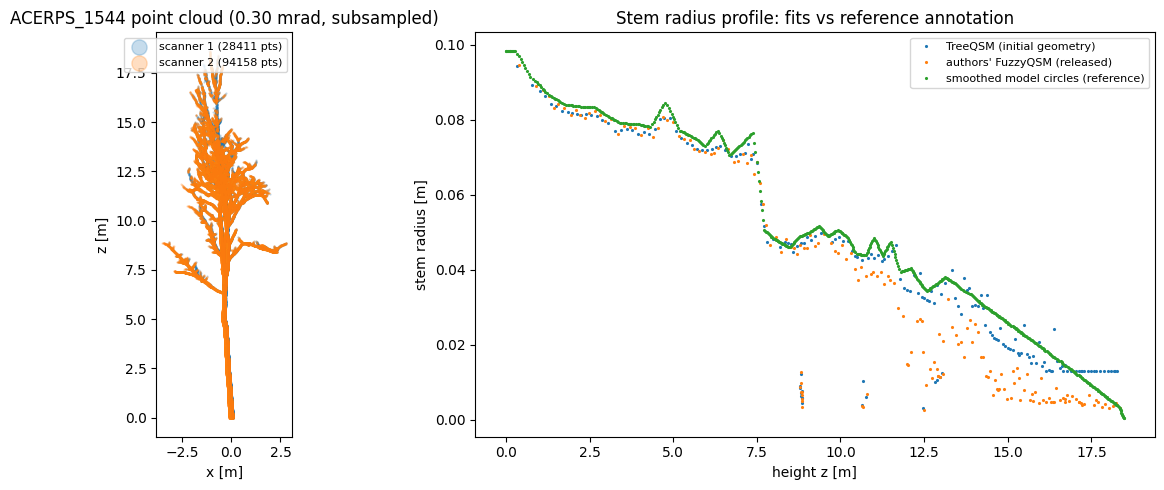

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
pcs=np.asarray(PC["point_cloud_cell"],dtype=object).ravel()
allpts=np.vstack([np.asarray(p) for p in pcs])
rng=np.random.default_rng(1); idx=rng.choice(len(allpts),size=min(40000,len(allpts)),replace=False)
fig,axes=plt.subplots(1,2,figsize=(13,5))
cols=["#1f77b4","#ff7f0e"]
for i,p in enumerate(pcs):
    p=np.asarray(p)
    axes[0].scatter(p[:,0],p[:,2],s=0.3,alpha=0.25,color=cols[i%2],label=f"scanner {i+1} ({len(p)} pts)")
axes[0].set_xlabel("x [m]"); axes[0].set_ylabel("z [m]"); axes[0].set_title(f"{TREE_ID} point cloud (0.30 mrad, subsampled)")
axes[0].legend(markerscale=20,fontsize=8); axes[0].set_aspect("equal")

rad_d=np.asarray(cyld["radius"]).ravel(); rad_f=np.asarray(cylf["radius"]).ravel()
st_d=np.asarray(cyld["start"]).ravel().reshape(-1,3); st_f=np.asarray(cylf["start"]).ravel().reshape(-1,3)
ax_d=np.asarray(cyld["axis"]).ravel().reshape(-1,3); ax_f=np.asarray(cylf["axis"]).ravel().reshape(-1,3)
L_d=np.asarray(cyld["length"]).ravel(); L_f=np.asarray(cylf["length"]).ravel()
h_d=st_d[:,2]+L_d*ax_d[:,2]/2; h_f=st_f[:,2]+L_f*ax_f[:,2]/2
m_d=bo_d==0; m_f=bo_f==0
axes[1].plot(h_d[m_d],rad_d[m_d],".",ms=2.5,label="TreeQSM (initial geometry)")
axes[1].plot(h_f[m_f],rad_f[m_f],".",ms=2.5,label="authors' FuzzyQSM (released)")
cg=np.asarray(s["Smoothed_Model_Circle_Geometry"]).flat[0]
cgc=np.asarray(cg["centre"]).ravel().reshape(-1,3); cgr=np.asarray(cg["radius"]).ravel(); cgb=np.asarray(cg["BranchOrder"]).ravel().astype(int)
axes[1].plot(cgc[cgb==0][:,2],cgr[cgb==0],".",ms=2.5,label="smoothed model circles (reference)")
axes[1].set_xlabel("height z [m]"); axes[1].set_ylabel("stem radius [m]")
axes[1].set_title("Stem radius profile: fits vs reference annotation")
axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Volume metric (exact transcription).** The authors' volume metric is `pi*r^2*L` per cylinder, summed per branch order; the **stem** is branch order 0 and **branches** are all higher orders (`QSM_Branch_Metrics.m` lines 22, `QSM_Tree_Metrics.m` lines 34–36, using the *modified* `radius` field). We transcribe this in Python and apply it to the released TreeQSM and FuzzyQSM; the ground truth is the authors' precomputed smoothed-model metrics (`Smoothed_Model_Metrics.treedata`).

**体積計算（JA）：** 著者の定義どおり `pi*r^2*L` を枝順ごとに合計します（幹=枝順0）。 ground truth は著者計算済みの平滑モデル体積です。

In [ ]:
import pandas as pd
def qsm_volumes(cyl):
    r=np.asarray(cyl["radius"]).ravel().astype(float)
    L=np.asarray(cyl["length"]).ravel().astype(float)
    bo=np.asarray(cyl["BranchOrder"]).ravel().astype(int)
    vol=np.pi*r**2*L
    return dict(total=float(vol.sum()), stem=float(vol[bo==0].sum()), branch=float(vol[bo>0].sum()), n=len(r))
def treedata_volumes(td):
    return dict(total=float(np.asarray(td["TotalVolume"]).ravel()[0]),
                stem=float(np.asarray(td["TrunkVolume"]).ravel()[0]),
                branch=float(np.asarray(td["BranchVolume"]).ravel()[0]))
v_tq=qsm_volumes(cyld); v_fq=qsm_volumes(cylf); v_gt=treedata_volumes(td_sm)
rows=[]
for name,v in [("TreeQSM (released)",v_tq),("FuzzyQSM (released)",v_fq),("Smoothed model (ground truth)",v_gt)]:
    rows.append(dict(method=name,total_m3=v["total"],stem_m3=v["stem"],branch_m3=v["branch"]))
vol_df=pd.DataFrame(rows)
rel=lambda v,g: 100*(v-g)/g
summary=pd.DataFrame({
  "relative volume error vs smoothed model [%]":
    [rel(v_tq["total"],v_gt["total"]), rel(v_fq["total"],v_gt["total"])],
  "stem [%]":[rel(v_tq["stem"],v_gt["stem"]), rel(v_fq["stem"],v_gt["stem"])],
  "branch [%]":[rel(v_tq["branch"],v_gt["branch"]), rel(v_fq["branch"],v_gt["branch"])],
},index=["TreeQSM","FuzzyQSM"]).round(2)
print(vol_df.round(4).to_string(index=False))
print()
print(summary.to_string())

                       method  total_m3  stem_m3  branch_m3
           TreeQSM (released)    0.3361   0.1947     0.1413
          FuzzyQSM (released)    0.3536   0.1840     0.1696
Smoothed model (ground truth)    0.3758   0.2024     0.1734

          relative volume error vs smoothed model [%]  stem [%]  branch [%]
TreeQSM                                        -10.58     -3.79       -18.5
FuzzyQSM                                        -5.92     -9.09        -2.2


**Metric cross-check.** `QSM_Fuzzy.treedata` stores the authors' own computed volumes (from `QSM_Tree_Metrics.m` inside the authors' MATLAB run). Our independent Python transcription must agree with it — this validates the port. (TreeQSM's own `treedata` is stored in litres by the TreeQSM toolbox, so it is compared after unit conversion.)

**検算（JA）：** 著者が保存した `QSM_Fuzzy.treedata` と我々のPython計算を照合し、移植の正しさを確認します。

In [ ]:
td_fq=flat(QF,"treedata")
ours=v_fq; authors=treedata_volumes(td_fq)
print("quantity        ours[m^3]   authors'treedata[m^3]  abs.diff")
for k in ("total","stem","branch"):
    print(f"{k:8s} {ours[k]:12.5f} {authors[k]:16.5f} {abs(ours[k]-authors[k]):10.2e}")
td_dq=flat(QD,"treedata")
litres=float(np.asarray(td_dq["TotalVolume"]).ravel()[0])
print()
print(f"TreeQSM treedata.TotalVolume = {litres:.1f} (litres) -> {litres/1000:.5f} m^3; our sum(pi r^2 L) = {v_tq['total']:.5f} m^3")

quantity        ours[m^3]   authors'treedata[m^3]  abs.diff
total         0.35359          0.35309   5.03e-04
stem          0.18401          0.18350   5.03e-04
branch        0.16958          0.16958   2.78e-17

TreeQSM treedata.TotalVolume = 336.1 (litres) -> 0.33607 m^3; our sum(pi r^2 L) = 0.33607 m^3


**Result graph and CSV export.** Relative volume error of each method against the smoothed-model ground truth for this single tree (an additional visualization created for this notebook, not an author figure). The paper's dataset-level averages (abstract): total −6.3 % (FuzzyQSM) vs −16.9 % (TreeQSM); branch −2.2 % vs −22.2 %.

**結果グラフ（JA）：** 平滑モデル基準の相対体積誤差（この notebook で追加作成した図であり、論文の図ではありません）。CSV も保存します。

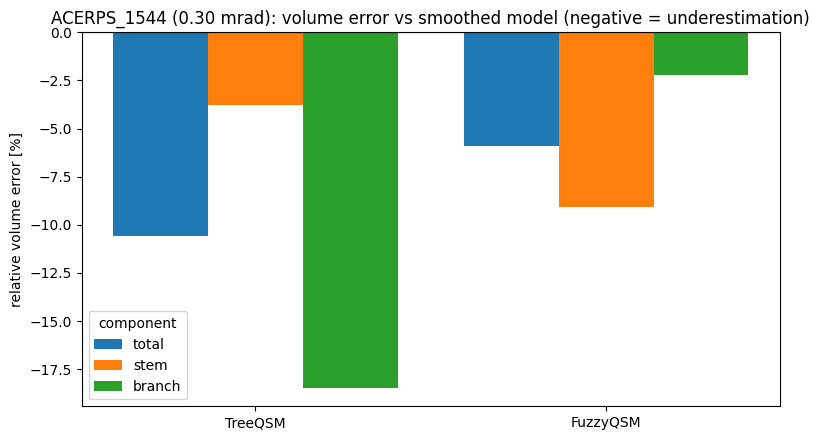

saved /content/fuzzyqsm_volume_comparison.csv and fuzzyqsm_relative_volume_error.csv


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
fig,ax=plt.subplots(figsize=(8,4.5))
methods=["TreeQSM","FuzzyQSM"]; x=np.arange(2); w=0.27
for i,(col,label) in enumerate([("total","total"),("stem","stem"),("branch","branch")]):
    err=[rel(v_tq[col],v_gt[col]),rel(v_fq[col],v_gt[col])]
    ax.bar(x+(i-1)*w,err,width=w,label=label)
ax.axhline(0,color="k",lw=0.8)
ax.set_xticks(x); ax.set_xticklabels(methods)
ax.set_ylabel("relative volume error [%]")
ax.set_title(f"{TREE_ID} (0.30 mrad): volume error vs smoothed model (negative = underestimation)")
ax.legend(title="component")
plt.tight_layout(); plt.show()
vol_df.to_csv("/content/fuzzyqsm_volume_comparison.csv",index=False)
summary.to_csv("/content/fuzzyqsm_relative_volume_error.csv")
print("saved /content/fuzzyqsm_volume_comparison.csv and fuzzyqsm_relative_volume_error.csv")

**One-cylinder demonstration of the actual method.** The paper's core computation is the per-cylinder fuzzy fit (expected Mahalanobis distance, authors' `Fuzzy_QSM_Infinite_Cylinder_Fitting.m`). Running all 3635 cylinders is out of scope; we execute the **authors' unmodified function** on one deterministic stem cylinder: the stem cylinder whose point count is **closest to 300** (recorded: 281 points). Expected runtime ≈ 80 s (measured on the validation date).

**単一円筒のフィット（JA）：** 著者の関数をそのまま Octave で実行します（点数が300に最も近い幹円筒、281点、約80秒）。

In [ ]:
import numpy as np
pmd_ind=np.asarray(pmd["CylInd"],dtype=object).ravel()
cnt=np.array([a.size for a in pmd_ind])
stem=np.where(bo_d==0)[0]
j=int(stem[np.argmin(np.abs(cnt[stem]-300))])
print("selected stem cylinder (0-based index):",j,"| points:",int(cnt[j]),
      "| TreeQSM radius: %.5f m"%rad_d[j],"| authors' FuzzyQSM radius: %.5f m"%rad_f[j])
open("/content/cyl_index.txt","w").write(str(j+1))

selected stem cylinder (0-based index): 44 | points: 281 | TreeQSM radius: 0.07081 m | authors' FuzzyQSM radius: 0.06876 m


2

**Run the authors' fitting code under Octave.** The script below builds the fitting inputs exactly as the authors' orchestrator `Wytham_FuzzyQSM_Fitting.m`/`Fuzzy_QSM_Fitting.m` do (per-scanner point subsets from `pmdistance.CylInd`, `sigma_range_device = sigma_range_0`, `bounds_margin = 0.50` from `Wytham_FuzzyQSM_Fitting.m` line 24), then calls the authors' `Fuzzy_QSM_Infinite_Cylinder_Fitting.m` — unchanged — with the three labeled compatibility files on the path.

**著者コードの実行（JA）：** 著者のオーケストレータと同じ入力構成で、未改変の `Fuzzy_QSM_Infinite_Cylinder_Fitting.m` を実行します（互換ファイル3点はAI生成）。

In [ ]:
import subprocess, time
lines=[
'warning("off","all");',
'pkg load statistics;',
'addpath("/content/fuzzyqsm_code/FuzzyQSM");',
'addpath("/content/fuzzyqsm_code/Geometry/Projection");',
'addpath("/content/fuzzyqsm_code/Geometry/Rotation");',
'addpath("/content/fuzzyqsm_code/Geometry/Shapes");',
'addpath("/content/fuzzyqsm_code/Geometry/Sampling");',
'addpath("/content/fuzzyqsm_code/Geometry/Intersections");',
'addpath("/content/fuzzyqsm_code/Geometry/Relative_Geometry");',
'addpath("/content/fuzzyqsm_code/Shape_Fitting/Cylinders");',
'addpath("/content/fuzzyqsm_code/Shape_Fitting/Circles");',
'addpath("/content/fuzzyqsm_code/Multivariate_Gaussian");',
'addpath("/content/fuzzyqsm_code/Laser_Properties");',
'addpath("/content/fuzzyqsm_code/Matrix");',
'addpath("/content/fuzzyqsm_code/Roots");',
'addpath("/content/fuzzyqsm_code/Structures");',
'addpath("/content/fuzzyqsm_code/Point_Cloud_Processing");',
'addpath("/content/fuzzyqsm_code/Miscellaneous");',
'addpath("/content");',
'S=load("/content/data/FuzzyQSM_Data/Point_Clouds/030_beamdivergence/'+TREE_ID+'_Point_Cloud.mat");',
'PC=S.Point_Cloud_Data_n; SP=S.Scanner_Parameters; SC=S.Scanning_Parameters;',
'SP.sigma_range_device=SP.sigma_range_0;',
'D=load("/content/data/FuzzyQSM_Data/TreeQSMs/030_beamdivergence/'+TREE_ID+'_Discrete_QSM.mat");',
'Q=D.QSM_Discrete;',
'cyl=Q.cylinder; pmd=Q.pmdistance;',
'c=load("/content/cyl_index.txt");',
'np=PC.number_points_list;',
'np=np(:);',
'cum=[0; cumsum(np)];',
'idx=pmd.CylInd{c};',
'pc_all=vertcat(PC.point_cloud_cell{:});',
'pc_cell=cell(1,numel(np)); cnt=zeros(1,numel(np));',
'for s=1:numel(np)',
'  sel=idx>=cum(s)+1 & idx<=cum(s+1);',
'  pc_cell{s}=pc_all(idx(sel),:);',
'  cnt(s)=sum(sel);',
'end',
'keep=cnt>0;',
'PCC=struct("point_cloud_cell",{pc_cell(keep)},"number_points_list",cnt(keep));',
'SCL=struct("Scanner_loc_cell",{SC.Scanner_loc_cell(keep)},"number_scanners",sum(keep));',
'FP=struct("Fuzzy_Vector",true,"bounds_margin",0.50);',
'Init_Cylinder=struct("start",cyl.start(c,:), "axis",cyl.axis(c,:), "radius",cyl.radius(c), "length",cyl.length(c));',
'disp(strcat("fitting cylinder ",num2str(c)," points ",num2str(sum(cnt))," init r ",num2str(cyl.radius(c))));',
't0=tic;',
'[Fuzzy_Inf_Cylinder, Distributions]=Fuzzy_QSM_Infinite_Cylinder_Fitting(Init_Cylinder,PCC,FP,SP,SCL);',
'dt=toc(t0);',
'disp(strcat("FIT DONE s=",num2str(dt)," radius=",num2str(Fuzzy_Inf_Cylinder.radius)));',
'save("-v7","/content/refit_result.mat","Fuzzy_Inf_Cylinder","Init_Cylinder","c");',
]
open("/content/fuzzy_fit_one.m","w").write(chr(10).join(lines)+chr(10))
t0=time.time()
r=subprocess.run(["octave","--no-gui","--quiet","/content/fuzzy_fit_one.m"],capture_output=True,text=True,timeout=1800)
print(r.stdout[-2000:])
if r.returncode!=0: print("STDERR:",r.stderr[-2000:])
assert r.returncode==0, "Octave fit failed"
print(f"Octave fit wall time: {time.time()-t0:.1f} s")

fitting cylinder45 points281 init r0.070805
FIT DONE s=79.4054 radius=0.060881

Octave fit wall time: 81.5 s


**Refit vs released references.** We compare (a) the TreeQSM initial radius, (b) the authors' released FuzzyQSM radius, and (c) our Octave refit of the authors' own function. Note that (b) contains the authors' **post-fitting `Branch_Radius_Correction`** (taper/parent corrections applied after the optimizer, `Fuzzy_QSM_Fitting.m` line 192), while our single-cylinder refit is the **raw optimizer output** — moderate systematic differences are therefore expected and are reported honestly rather than tuned away.

**比較（JA）：** TreeQSM初期値・著者公開値・Octave再フィットを比較します。公開値にはフィッティング後の `Branch_Radius_Correction` が含まれるため、生の最適化出力である再フィットとは系統的な差が生じ得ます。

In [ ]:
import scipy.io as sio, numpy as np
import pandas as pd
res=sio.loadmat("/content/refit_result.mat",struct_as_record=True,squeeze_me=False)
r_fit=float(np.asarray(flat(res,"Fuzzy_Inf_Cylinder")["radius"]).ravel()[0])
tbl=pd.DataFrame({
 "radius [m]":[rad_d[j], rad_f[j], r_fit],
 "difference vs released FuzzyQSM [m]":[rad_d[j]-rad_f[j], 0.0, r_fit-rad_f[j]],
},index=["TreeQSM initial","authors' FuzzyQSM (released, post-corrected)","Octave refit (raw, authors' function)"]).round(5)
print(tbl.to_string())
print()
print(f"refit vs released FuzzyQSM: {100*(r_fit-rad_f[j])/rad_f[j]:+.1f} %")

                                              radius [m]  difference vs released FuzzyQSM [m]
TreeQSM initial                                  0.07081                              0.00204
authors' FuzzyQSM (released, post-corrected)     0.06876                              0.00000
Octave refit (raw, authors' function)            0.06088                             -0.00788

refit vs released FuzzyQSM: -11.5 %


## Interpretation and limitations

**English.** For the single tree `ACERPS_1544` (0.30 mrad), the released FuzzyQSM reconstructs the smoothed-model volume markedly better than TreeQSM (see the relative-error table and graph above), consistent in direction — and for this tree closely in magnitude — with the paper's dataset-level averages (total −6.3 % vs −16.9 %; branch −2.2 % vs −22.2 %; abstract). The authors' own function runs end-to-end under Octave on a stem cylinder and produces a fitted radius of the same order as the released values; the remaining difference is expected because the released FuzzyQSM radii additionally include `Branch_Radius_Correction`, and because our adapter substitutes Octave `sqp` for MATLAB `fmincon` (interior-point). **This is a one-tree, partial demonstration: it does not verify the paper's full pipeline or dataset-level statistics.** Limitations: (i) optimizer substitution and the unreleased-helper replacement are AI-generated; (ii) one cylinder refitted out of 3635; (iii) 5.96 GB download required by the single-zip publication; (iv) execution measured on a Colab CPU runtime, Octave 8.4.0, 2026-10-24.

**日本語（JA）：** 単一木 `ACERPS_1544`（0.30 mrad）において、公開済み FuzzyQSM は TreeQSM より平滑モデル体積に近く、論文のデータセット平均（総体積 −6.3% vs −16.9%、枝 −2.2% vs −22.2%）と定性的に一致します。著者の関数自体も Octave 上で end-to-end 実行でき、公開値と同程度の半径を返しました。差の主因は、公開値がフィッティング後の半径補正を含むことと、`fmincon`（内点法）を `sqp` に置き換えた互換アダプタです。本ノートブックは1木・部分再現であり、論文の統計全体を検証するものではません。

## References and provenance

- V. Verhoeven, X. Liang, J. Peřucha (authors as listed on the article), *FuzzyQSM: A Novel Tree Structure Reconstruction Approach Using Uncertainty*, Remote Sensing 18(18):3244, 2026. DOI 10.3390/rs18183244.
- Author code: https://github.com/InverseTampere/FuzzyQSM commit `0e8496b52df652377af5fdb4fb5baa66ad8341a6` (GPL-3.0). Key functions: `Fuzzy_QSM_Infinite_Cylinder_Fitting.m`, `Fuzzy_QSM_Fitting.m`, `QSM_Branch_Metrics.m`, `QSM_Tree_Metrics.m`, `Wytham_FuzzyQSM_Fitting.m`.
- Data: Zenodo record 20793837 (version record), `FuzzyQSM_Data.zip`, 5,963,820,799 bytes, md5 `129c5d244c793b3b56ffc9b1fb4a65dd`, CC-BY-4.0. Sample: `ACERPS_1544`, 0.30 mrad beam divergence, 2 scan positions.
- Reference values quoted from the paper's abstract via the Tampere University research portal record (full text was not required for this scope).
- AI-generated compatibility files are marked in their headers; all other `.m` files run unmodified from the pinned commit.